In [1]:
#imports 

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import polars as pl
from collections import namedtuple

%matplotlib widget

In [2]:
data_coupled    = pl.read_parquet("data_complete/2026_10_27_18h58.parquet")

In [3]:
data_uncoupled  = pl.read_parquet("data_complete/2026_10_21_11h44.parquet")

In [4]:
exp_coupled = data_coupled.group_by(
    pl.col("f")
).agg(
    pl.col("pow1").max().alias("pow1max"),
    pl.col('Rload')
)

exp_uncoupled = data_uncoupled.group_by(
    pl.col("f")
).agg(
    pl.col("pow1").max().alias("pow1max"),
    pl.col("pow2").max().alias("pow2max"),
    (pl.col('pow1')+pl.col('pow2')).max().alias('powtot')
)

# Ropt_coupled = []
# for f in (results_coupled["f"]):
#         p = results_coupled.filter(pl.col("f") == f)["pow1max"]
#         d = data_coupled.filter((pl.col("f")==f) & (pl.col("pow1") == p))["Rload"]
#         Ropt_coupled.append(d[0])

# Ropt_uncoupled_1 = []
# Ropt_uncoupled_2 = []
# for f in (results_uncoupled["f"]):
#         p1 = results_uncoupled.filter(pl.col("f") == f)["pow1max"]
#         p2 = results_uncoupled.filter(pl.col("f") == f)["pow2max"]
#         d1 = data_uncoupled.filter((pl.col("f")==f) & (pl.col("pow1") == p1))["Rload"]
#         d2 = data_uncoupled.filter((pl.col("f")==f) & (pl.col("pow2") == p2))["Rload"]
#         Ropt_uncoupled_1.append(d1)
#         Ropt_uncoupled_2.append(d2)

In [5]:
# opti python à la main 

# f0_d    = 130.6
# w0_d    = f0_d * 2 * jnp.pi
# Cpre_d  = 4.5e-09 
# Cpim_d  = -2.5e-11
# km2_d   = 0.816
# Q_d     = 205
# M_d     = 5.2e-3
# gamma_d = 0.12

# f0_c    = 99.8
# w0_c    = f0_c * 2 * jnp.pi
# Cpre_c  = 5.85e-09
# Cpim_c  = -6.7e-11
# km2_c   = 0.31
# Q_c     = 130
# M_c     = 0.005     
# gamma_c = 0.115

# # opti matlab 

# w0_d = 8.211455e+02 
# Cpre_d = 4.146947e-09 
# Cpim_d = -1.448657e-11 
# km2_d = 8.183730e-01 
# Q_d = 2.141478e+02 
# M_d = 8.782316e-03 
# gamma_d = 8.853933e-02

# w0_c = 6.273995e+02 
# Cpre_c = 6.302375e-09 
# Cpim_c = -8.076229e-11 
# km2_c = 3.110795e-01 
# Q_c = 9.945859e+01 
# M_c = 5.268166e-03 
# gamma_c = 1.211506e-01


# opti alamano 
# gamma_c = gamma_d = 0.0818

w0_d = 8.21e+02 
Cpre_d = 4.15e-09 
Cpim_d = -4.5e-11 
km2_d = 8.18e-01 
Q_d = 206.9
M_d = 8.93e-03 
Bf_d = 7.30474e-4

w0_c = 6.27e+02 
Cpre_c = 6.30e-09 
Cpim_c = -5.08e-10
km2_c = 3.11e-01 
Q_c = 130
M_c = 9.77e-03 
Bf_c = 7.30474e-4



In [6]:
frequencies_list = jnp.asarray(data_uncoupled['f'].unique())
omegas_list      = frequencies_list * 2 * jnp.pi
resistances_list = jnp.asarray(data_uncoupled['Rload'].unique())


In [10]:
0.15/0.0885

1.694915254237288

In [ ]:
ProtoParams = namedtuple('ProtoParams', ['w0', 'M', 'Q', 'Cp', 'km2', 'ksi'])
ManipParams = namedtuple('ManipParams', ['w', 'R', 'Ce', 'tau'])

ProtoDavid = ProtoParams(w0_d, M_d, Q_d, Cpre_d+1.j*Cpim_d, km2_d, 0.088)
ProtoCoude = ProtoParams(w0_c, M_c, Q_c, Cpre_c+1.j*Cpim_c, km2_c, 0.088)

In [227]:
def systems_signals(proto1: ProtoParams, proto2: ProtoParams, manip: ManipParams):
    """
    returns x1, x2, phi_x1, phi_x2, v1, v2, P1in, P2in
    position resonator 1, voltage resonator 1
    position resonator 2, voltage resonator 2
    computed by analytical analysis 
    for the two couples linear resonators system
    """

    w01      = proto1.w0
    M1       = proto1.M
    Q1       = proto1.Q
    Cp1      = proto1.Cp
    km2_1    = proto1.km2
    ksi1   = proto1.ksi

    w02      = proto2.w0
    M2       = proto2.M
    Q2       = proto2.Q
    Cp2      = proto2.Cp
    km2_2    = proto2.km2
    ksi2   = proto2.ksi

    w       = manip.w
    # r       = 0.764
    s       = manip.tau
    c      = manip.Ce

    R       = 2*manip.R
    tau1    = R*Cp1
    tau2    = R*Cp2
    
    alpha1 = jnp.sqrt(km2_1 * M1 * w01**2 * jnp.real(Cp1))
    alpha2 = jnp.sqrt(km2_2 * M2 * w02**2 * jnp.real(Cp2))

    A1 = (Cp1*(1+c + 1/(tau1*1.j*w)))/alpha1
    A2 = (Cp2*(1+c + 1/(tau2*1.j*w)))/alpha2
    B1 = s * c*Cp1/alpha1
    B2 = s * c*Cp2/alpha2
    C1 = 1.j*w*w01/Q1+w01**2-w**2
    C2 = 1.j*w*w02/Q2+w02**2-w**2
    D1 = alpha1/M1
    D2 = alpha2/M2
    E = (C2*A1*A2+D2*A1)/B1 - C2*B2
    F = (C2*A2+D2)/B1

    v1 = ksi2*(F+C1)/(E*C1+F*D1)
    x1 = (ksi1-v1*D1)/C1
    v2 = (v1*A1-x1)/B1
    x2 = v2*A2-v1*B2

    P1elec = jnp.real(alpha1*v1*jnp.conjugate(1.j*w*x1))/2
    P2elec = jnp.real(alpha2*v2*jnp.conjugate(1.j*w*x2))/2


    Ptotelec = P1elec+P2elec
    
    
    return {'P1elec': P1elec, 'P2elec': P2elec, 
            'Ptotelec': Ptotelec,} 


In [228]:
# vmap pour faire sur omega et r

v_wr1 = jax.vmap(
    jax.vmap(
        systems_signals,
        in_axes=(
            None, 
            None, 
            ManipParams(
                None, 
                0, 
                None, 
                None,
            ),
        ),
    ),
    in_axes = (
        None, 
        None, 
        ManipParams(
            0, 
            None, 
            None, 
            None,
        )
    ),
)

In [229]:
def wr1_argmax_over_R(P, n1):
    idx_P = jnp.argmax(P, axis=1)
    i_opt = jnp.unravel_index(idx_P, (n1)) # unravel indices
    return i_opt # return indices
 
def extract_indices_optr1(P_np):
    nW, n1 = P_np.shape
    i_opt = wr1_argmax_over_R(P_np, n1)
    R1_opt = resistances_list[i_opt]
    return R1_opt

In [230]:
voptimize_w_r1 = jax.vmap(
    systems_signals, 
    in_axes=(
        None, 
        None, 
        ManipParams(
            0, 
            0, 
            None, 
            None,
        )
    ),
)

In [231]:
def optimize_w_r1(proto1, proto2, manip):
    
    signals = v_wr1(proto1, proto2, manip)

    R1_opt_wr1 = extract_indices_optr1(signals['Ptotelec'])
    
    param = ManipParams(manip.w, R1_opt_wr1, manip.Ce, manip.tau)
    
    return voptimize_w_r1(proto1, proto2, param), R1_opt_wr1

In [240]:
simu_coupled, Ropt_coupled = optimize_w_r1(ProtoDavid, ProtoCoude, ManipParams(omegas_list, resistances_list, 1e-12*ProtoCoude.Cp, 1))
# simu_uncoupled, Ropt_uncoupled = optimize_w_r1(ProtoDavid, ProtoCoude, ManipParams(omegas_list, resistances_list, 1e-12, 1))

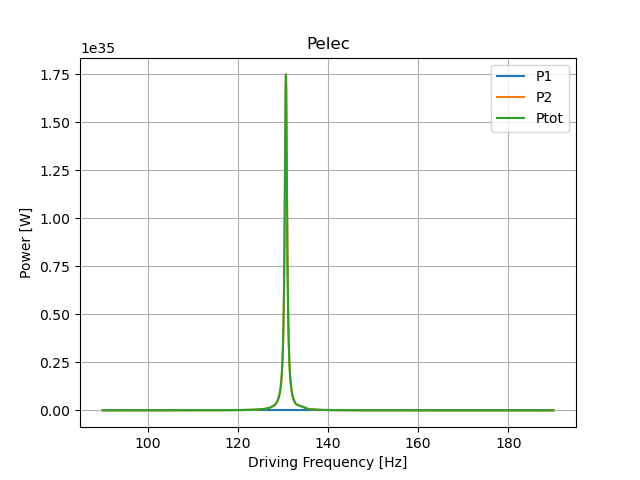

In [241]:
plt.figure()
plt.plot(frequencies_list, simu_coupled['P1elec'], label = "P1")
plt.plot(frequencies_list, simu_coupled['P2elec'], label = "P2")
plt.plot(frequencies_list, simu_coupled['Ptotelec'], label = "Ptot")
plt.xlabel("Driving Frequency [Hz]")
plt.ylabel("Power [W]")
plt.title("Pelec")
plt.legend()
# plt.yscale('log')
plt.grid()
plt.show()

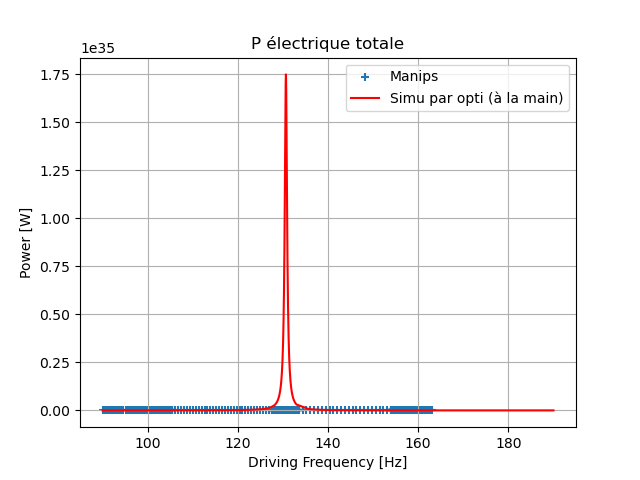

In [242]:
plt.figure()
plt.scatter(jnp.asarray(exp_coupled["f"]), jnp.asarray(exp_coupled["pow1max"]), marker = '+', label = "Manips")
# plt.scatter(jnp.asarray(exp_uncoupled["f"]), jnp.asarray(exp_uncoupled["pow2max"]), marker = '+', label = "Manips")
plt.plot(frequencies_list, simu_coupled['Ptotelec'], 'r-', label = "Simu par opti (à la main)")
plt.xlabel("Driving Frequency [Hz]")
plt.ylabel("Power [W]")
plt.title("P électrique totale")
plt.legend()
# plt.yscale('log')
plt.grid()
plt.show()

In [243]:
# plt.figure()
# plt.subplot(2, 1, 1)
# plt.scatter(frequencies_list, r_coupled["Ptotelec"], marker='+', label = "coupled")
# # plt.scatter(results_uncoupled["f"], results_uncoupled["pow1max"], marker='+', label = "uncoupled")
# plt.title('Power optimized for each frequency \nand corresponding resistance value')
# plt.ylabel('Power')
# plt.grid()

# plt.subplot(2, 1, 2)
# plt.scatter(results_uncoupled["f"], Ropt_uncoupled, marker='+', label = "coupled")
# plt.scatter(frequencies_list, Ropt_uncoupled, marker='+', label = "coupled")
# # plt.scatter(results_uncoupled["f"], Ropt_uncoupled_1, marker='+', label = "uncoupled")
# # plt.scatter(results_uncoupled["f"], Ropt_uncoupled_2, marker='+', label = "uncoupled")
# plt.ylabel('R')
# plt.yscale('log')
# plt.xlabel('Frequency [Hz]')
# plt.grid()

# plt.show()